# Volatility Calculation and Comparison

This notebook provides a sample comparison of some commonly used methods for estimating volatility:

1. Rolling historical volatility
2. Exponentially Weighted Moving Average (EWMA) volatility
3. GARCH(1,1) volatility

The objective is to examine how the volatility estimates produced by these methods change over time and how differently they respond to periods of market instability. The notebook also studies how the choice of rolling-window length affects historical volatility.

**Conventions:** throughout the notebook, returns are **simple daily returns in decimal form** (e.g. 0.012 = 1.2%), not log returns, and all volatilities are **daily** (not annualised). This keeps the estimates directly usable in one-day VaR, where a VaR of 0.025 means a 2.5% loss in price.

Before beginning the notebook, read and understand **Chapter 23: Estimating Volatilities and Correlations** from *Options, Futures, and Other Derivatives*, 11th Edition, by John C. Hull.

In [1]:
%pip install numpy pandas matplotlib yfinance arch statsmodels -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Data and Model Setup

We analyse daily simple returns for HDFC Bank (`HDFCBANK.NS`) from June 2020 to September 2026:

$$
r_t = \frac{P_t - P_{t-1}}{P_{t-1}}
$$

where $P_t$ is the adjusted closing price on day $t$. A long sample is used here because rolling windows of up to 200 days, and GARCH estimation, need a substantial history before they produce reliable estimates. Historical volatility will be estimated using 21-, 50-, 100-, and 200-day rolling windows.

For EWMA, we set the decay factor to $\lambda=0.94$, a commonly used value for daily financial data discussed in the volatility-estimation literature. It assigns 94% weight to the previous variance estimate and 6% to the latest squared return.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from arch import arch_model
from statsmodels.stats.diagnostic import het_arch

ticker = "HDFCBANK.NS"
start_date = "2020-06-01"
end_date = "2026-09-06"

windows = [21, 50, 100, 200]
lam = 0.94

In [3]:
data = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

price = data["Close"].squeeze()
returns = price.pct_change().dropna()

returns.head()

Date
2020-06-02    0.013517
2020-06-03    0.021229
2020-06-04   -0.020103
2020-06-05    0.031596
2020-06-08   -0.016887
Name: HDFCBANK.NS, dtype: float64

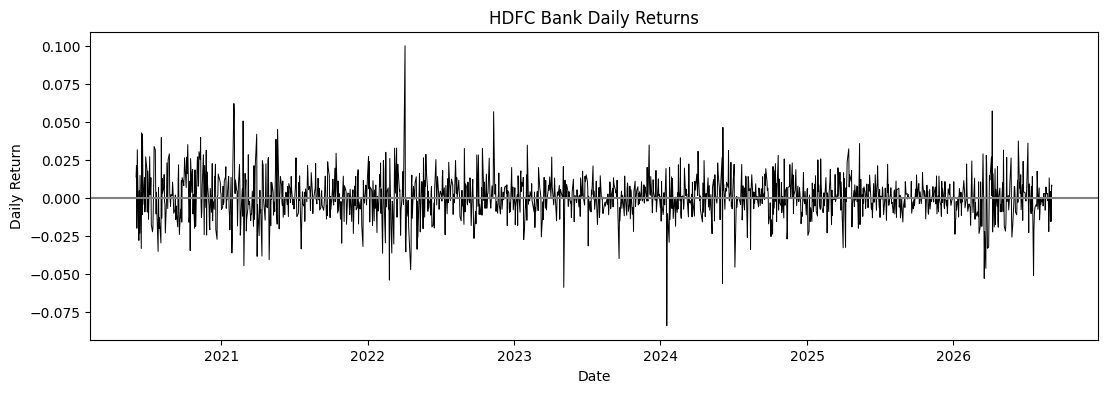

In [4]:
plt.figure(figsize=(13, 4))

plt.plot(returns, color="black", linewidth=0.7)
plt.axhline(0, color="grey")

plt.title("HDFC Bank Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.show()

## Rolling Historical Volatility

Historical volatility is calculated as the standard deviation of the previous $X$ daily returns:

$$
\sigma_{t}
=
\sqrt{
\frac{1}{X-1}
\sum_{i=1}^{X}
(r_{t-i}-\bar r)^2
}
$$

where $\bar r$ is the mean return over the same $X$ days. The result is a **daily** volatility; it is not annualised. The `shift(1)` ensures that the estimate for day $t$ uses only returns available before that day.

The calculation is repeated using 21-, 50-, 100-, and 200-day rolling windows. Shorter windows respond more quickly to recent observations but are less smooth, while longer windows use more historical information and change more gradually. All observations within a given window receive equal weight.

In [5]:
historical_vols = {}

for window in windows:
    historical_vols[window] = (
        returns.shift(1)
        .rolling(window)
        .std()
    )

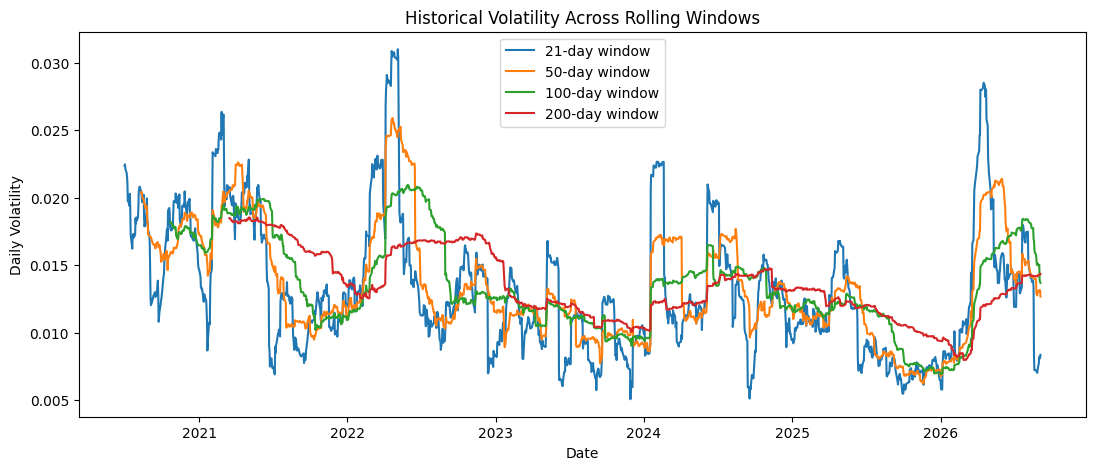

In [6]:
plt.figure(figsize=(13, 5))

for window in windows:
    plt.plot(
        historical_vols[window],
        label=f"{window}-day window"
    )

plt.title("Historical Volatility Across Rolling Windows")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

## EWMA Volatility

The Exponentially Weighted Moving Average model updates the variance estimate recursively:

$$
\sigma_t^2
=
\lambda\sigma_{t-1}^2
+
(1-\lambda)r_{t-1}^2
$$

Here, $\lambda$ is the decay factor:

$$
\lambda=0.94
$$

Therefore, 94% of the new variance estimate comes from the previous variance estimate, while 6% comes from the most recent squared return:

$$
\sigma_t^2
=
0.94\sigma_{t-1}^2+0.06r_{t-1}^2
$$

Unlike rolling historical volatility, EWMA does not assign equal weights or abruptly remove old observations. The weights decline exponentially, so recent returns have more influence than older returns.

In the code, `shift(1)` ensures that only information available before day $t$ is used. Pandas defines `alpha` as the weight on the newest observation, so `alpha = 1 - lambda = 0.06`. Finally, the daily variance is converted to daily volatility:

$$
\sigma_t = \sqrt{\sigma_t^2}
$$

In [7]:
ewma_var = (
    returns.shift(1).pow(2)
    .ewm(alpha=1-lam, adjust=False)
    .mean()
)

ewma_vol = np.sqrt(ewma_var)

## Test for ARCH Effects

Before estimating GARCH, we use Engle's ARCH LM test to check whether volatility clustering is present.

- Null hypothesis: no ARCH effects are present.
- Alternative hypothesis: ARCH effects are present.

The test uses 12 lags. A p-value below 0.05 rejects the null hypothesis and supports the use of a conditional volatility model such as GARCH.

In [8]:
arch_test = het_arch(returns * 100, nlags=12)

print("LM statistic:", arch_test[0])
print("LM p-value:", arch_test[1])

LM statistic: 65.56760117614505
LM p-value: 2.1407436704708844e-09


## GARCH(1,1) Volatility

The GARCH(1,1) model estimates conditional variance using:

$$
\sigma_t^2
=
\omega+\alpha u_{t-1}^2+\beta\sigma_{t-1}^2
$$

where:

- $\omega$ is the constant variance component.
- $u_{t-1}^2$ is the previous squared return shock.
- $\alpha$ measures the response of volatility to new information.
- $\sigma_{t-1}^2$ is the previous conditional variance.
- $\beta$ measures the persistence of past volatility.

The mean equation is specified as:

$$
r_t=\mu+u_t
$$

In the code, `p=1` includes one lag of the squared shock and `q=1` includes one lag of conditional variance. The parameters are estimated by maximum likelihood under the assumption of normally distributed innovations.

**Scaling note:** the model is estimated on returns multiplied by 100 (i.e. in percent). This is only for numerical stability. The conditional volatility is divided by 100 to convert it back to **daily volatility in decimal form**, consistent with the rest of the notebook.

Volatility persistence is measured by:

$$
\alpha+\beta
$$

For the estimated model:

$$
\alpha+\beta=0.076+0.888=0.964
$$

The persistence value is below but close to one, indicating that volatility shocks are expected to decline slowly over time.

In [9]:
model = arch_model(
    returns * 100,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)

result = model.fit(disp="off")

garch_vol = result.conditional_volatility / 100

print(result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            HDFCBANK.NS   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2663.90
Distribution:                  Normal   AIC:                           5335.81
Method:            Maximum Likelihood   BIC:                           5357.20
                                        No. Observations:                 1554
Date:                Wed, Oct 21 2026   Df Residuals:                     1553
Time:                        15:37:49   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0206  3.285e-02      0.626      0.531 

In [10]:
alpha = result.params["alpha[1]"]
beta = result.params["beta[1]"]

print("Alpha:", alpha)
print("Beta:", beta)
print("Persistence:", alpha + beta)

Alpha: 0.07596105927576084
Beta: 0.8878007041150073
Persistence: 0.9637617633907681


## Comparison of Volatility Estimates

The first panel plots daily HDFC Bank returns. The remaining panels compare EWMA and GARCH(1,1) volatility with historical volatility calculated using 21-, 50-, 100-, and 200-day windows.

Observe:

- How each method responds after a large return.
- Which estimates react most quickly to volatility changes.
- How long each estimate remains elevated after a shock.
- How the historical-volatility plot changes as the rolling window increases.
- Whether EWMA and GARCH produce similar or different volatility paths.
- Which methods appear smoother and which display sharper changes.

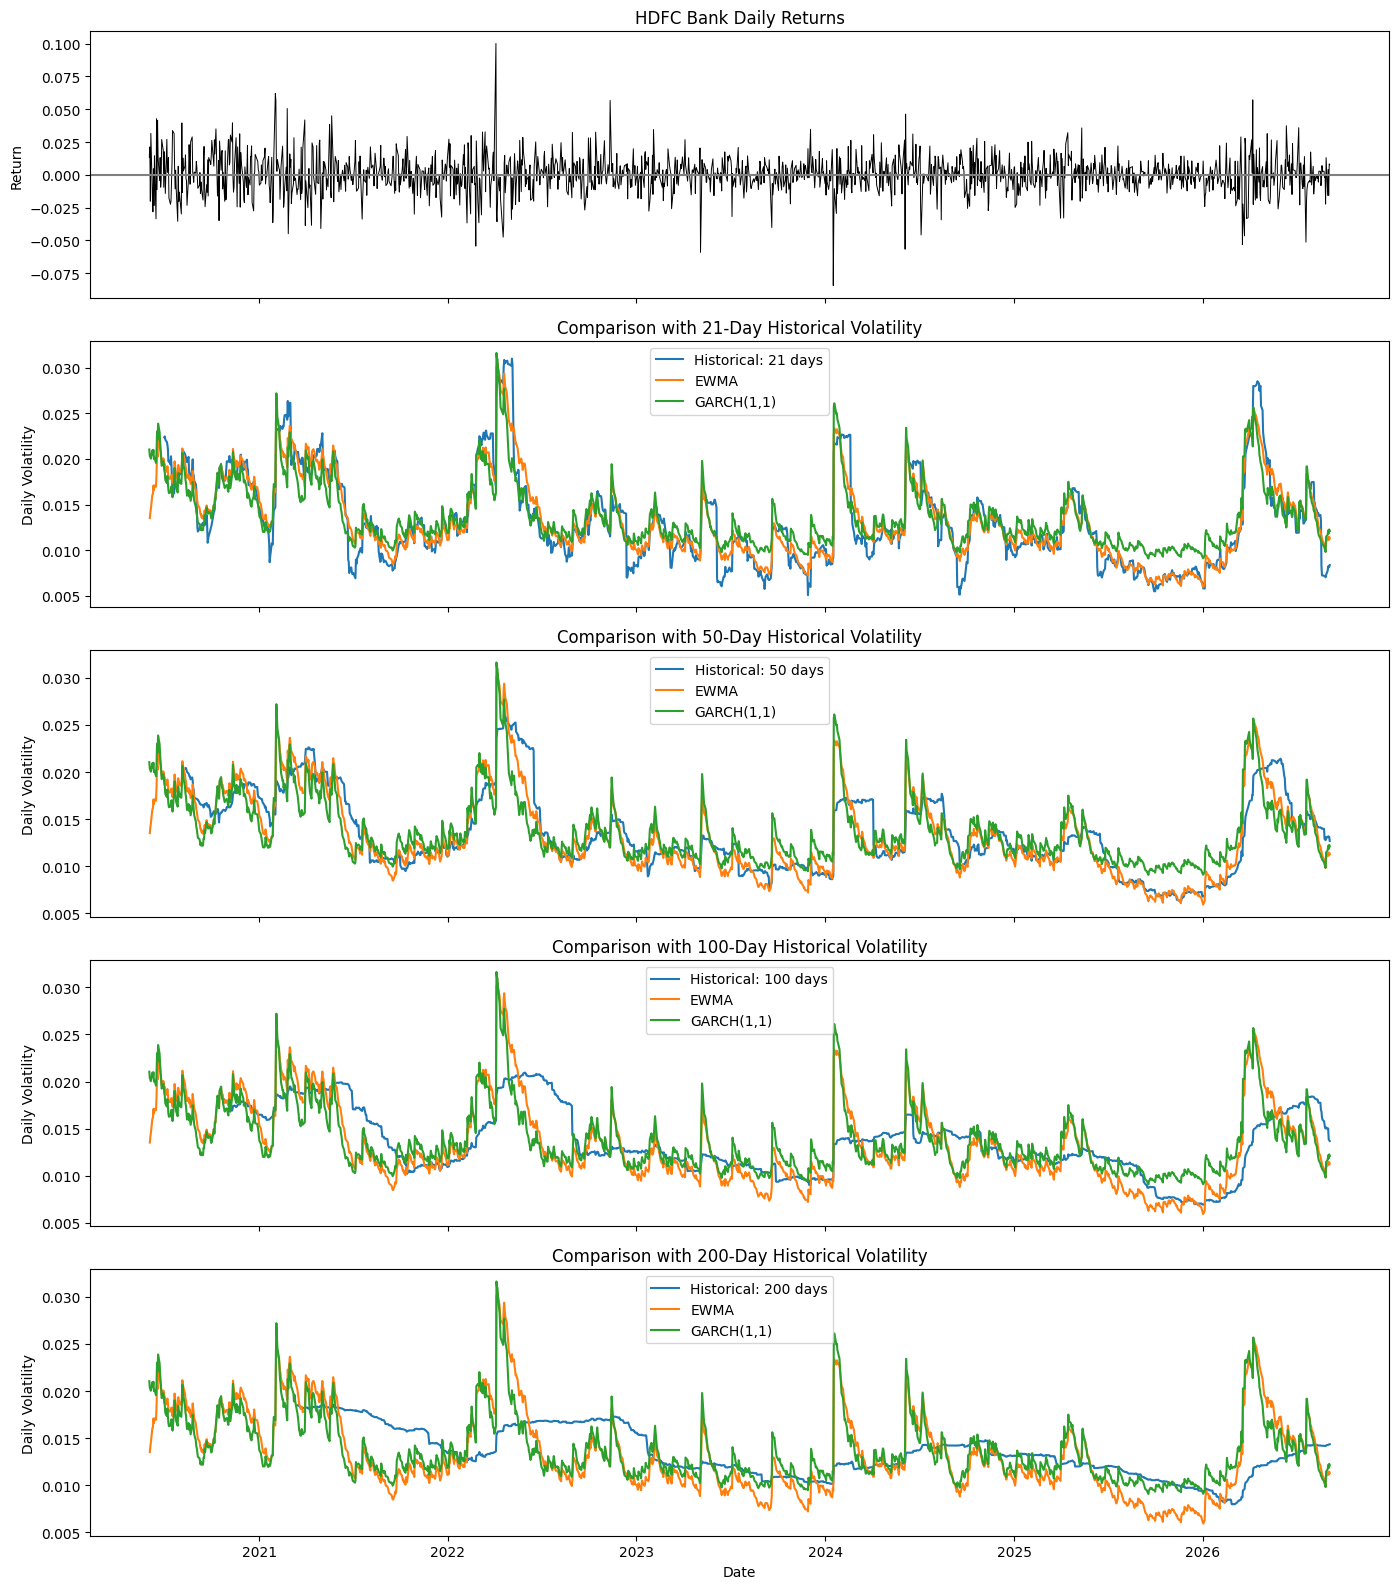

In [11]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(14, 16),
    sharex=True
)

axes[0].plot(returns, color="black", linewidth=0.7)
axes[0].axhline(0, color="grey")
axes[0].set_title("HDFC Bank Daily Returns")
axes[0].set_ylabel("Return")

for ax, window in zip(axes[1:], windows):
    ax.plot(
        historical_vols[window],
        label=f"Historical: {window} days"
    )
    ax.plot(ewma_vol, label="EWMA")
    ax.plot(garch_vol, label="GARCH(1,1)")

    ax.set_title(f"Comparison with {window}-Day Historical Volatility")
    ax.set_ylabel("Daily Volatility")
    ax.legend()

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()